In [81]:
import torch
import pandas as pd
import numpy as np

In [99]:
df = pd.read_csv("../data/processed/relaxase_oriT_dataset.csv")

df

,oriTDB_accession,oriTDB_id,nic site,relaxase_family,relaxase_sequence,host,sDBM,sDBM_pos,sDBM_sim_gap,oriT_nic_seq
0,100001,GAATAAGGGACAGTGAAGAAGGAACACCCGCTCGCGGGTGGGCCTA...,60..61,TraI,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...,Pseudomonas aeruginosa,HVPMRSIKK,"(4, 12)",3.985026,TATCCTGCC
1,100002,CCGGCCAGCCTCGCAGAGCAGGATTCCCGTTGAGCACCGCCAGGTG...,107..108,TraI,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...,Klebsiella aerogenes K8841,HVPMRSIKK,"(4, 12)",3.985026,TATCCTGCC
2,100003,CCAGTTTCTCGAAGAGAAACCGGTAAGTGCGCCCTCCC,31..32,MobA,MAIYHLTAKTGSRSGGQSARAKADYIQREGKYARDMDEVLHAESGH...,Escherichia coli,HLTAKTGSR,"(4, 12)",16.299099,AAGTGCGCC
3,100004,TTGCCCTATCCTGCATCGC,13..14,TaxC,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...,E. coli,VEKDYRVKR,"(4, 12)",0.642514,TATCCTGCA
4,100005,TTGCCCTATCCTGCATCGC,13..14,TaxC,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...,E. coli,VEKDYRVKR,"(4, 12)",0.642514,TATCCTGCA
...,...,...,...,...,...,...,...,...,...,...
1391,104307,GGATTTAGGTTTTTTTTTAATCGCTTCACATTTCGTTAGCATGCGC...,78..79,MobH,MMMNFRALYLCIKRILGIFSSQENDATSVMIEDISSLSPFAQILGD...,Enterobacter kobei strain 12379-yvys,NFRALYLCI,"(3, 11)",0.067639,AGTTTGGTT
1392,104309,GGATTTAGGTTTTTTTTTAATCGCTTCACATTTCGTTAGCATGCGC...,78..79,MobH,MMMNFRALYLCIKRILGIFSSQENDATSVMIEDISSLSPFAQILGD...,Enterobacter asburiae strain 16773-yvys,NFRALYLCI,"(3, 11)",0.067639,AGTTTGGTT
1393,104312,GGATTTAGGTTTTTTTTTAATCGCTTCACATTTCGTTAGCATGCGC...,78..79,MobH,MMMNFRALYLCIKRILGIFSSQENDATSVMIEDISSLSPFAQILGD...,Enterobacter kobei strain 11743-yvys,NFRALYLCI,"(3, 11)",0.067639,AGTTTGGTT
1394,104313,TATTTCATTTTTTGTTTTTTTAATCAGTTAGTTAGTGCGATTCATC...,62..63,MobF,MLDITTITRIDIASVVGYYADAKDDYYSKDSSFTAWHGQGAEALGL...,Enterobacter kobei strain 11743-yvys,SKDSSFTAW,"(27, 35)",0.767967,TAGGTGTAT


In [100]:
df = df.dropna(subset=['oriT_nic_seq'])

# remember to set sDBM threshold

df = df.drop(columns=['oriTDB_accession', 'oriTDB_id', 'nic site', 'host', 'sDBM_sim_gap'])

df

,relaxase_family,relaxase_sequence,sDBM,sDBM_pos,oriT_nic_seq
0,TraI,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...,HVPMRSIKK,"(4, 12)",TATCCTGCC
1,TraI,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...,HVPMRSIKK,"(4, 12)",TATCCTGCC
2,MobA,MAIYHLTAKTGSRSGGQSARAKADYIQREGKYARDMDEVLHAESGH...,HLTAKTGSR,"(4, 12)",AAGTGCGCC
3,TaxC,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...,VEKDYRVKR,"(4, 12)",TATCCTGCA
4,TaxC,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...,VEKDYRVKR,"(4, 12)",TATCCTGCA
...,...,...,...,...,...
1391,MobH,MMMNFRALYLCIKRILGIFSSQENDATSVMIEDISSLSPFAQILGD...,NFRALYLCI,"(3, 11)",AGTTTGGTT
1392,MobH,MMMNFRALYLCIKRILGIFSSQENDATSVMIEDISSLSPFAQILGD...,NFRALYLCI,"(3, 11)",AGTTTGGTT
1393,MobH,MMMNFRALYLCIKRILGIFSSQENDATSVMIEDISSLSPFAQILGD...,NFRALYLCI,"(3, 11)",AGTTTGGTT
1394,MobF,MLDITTITRIDIASVVGYYADAKDDYYSKDSSFTAWHGQGAEALGL...,SKDSSFTAW,"(27, 35)",TAGGTGTAT


In [101]:
negative_df = df.copy()

def shuffle_until_no_match(max_attempts=30000):

    minMatches = np.inf
    best_shuffle = None
    best_shuffle_same_ori_rows = None

    for _ in range(max_attempts):
        negative_df['oriT_nic_seq'] = np.random.permutation(negative_df['oriT_nic_seq'])

        boolarr = negative_df['oriT_nic_seq'].values == df['oriT_nic_seq'].values

        if not np.any(boolarr):
            print("Perfect shuffle")
            return

        if boolarr.sum() < minMatches:
            minMatches = boolarr.sum()
            best_shuffle_same_ori_rows = np.where(boolarr)[0]
            best_shuffle = negative_df.copy()

    
    print(best_shuffle_same_ori_rows)


    print("Failed")

    print(minMatches)

    return best_shuffle, best_shuffle_same_ori_rows, minMatches


best_negative_df, indices, minMatches = shuffle_until_no_match()


def mutate_ori_dataset(df, rows):

    bases = np.array(['A', 'C', 'T', 'G'])


    for row in rows:
        row = int(row)

        same_ori = df.iloc[row]['oriT_nic_seq']
        
        random_pos = random.randint(0, len(same_ori) - 1)

        current_base = same_ori[random_pos]

        possible_bases = bases[bases != current_base]
        random_base = random.choice(possible_bases)

        mutated_ori = (
            same_ori[:random_pos]
            + random_base
            + same_ori[random_pos + 1:]
        )

        mutated_ori = same_ori[:random_pos] + random_base + same_ori[random_pos + 1:]
        print(same_ori)
        print(mutated_ori)

        df.iloc[row, df.columns.get_loc('oriT_nic_seq')] = mutated_ori

mutate_ori_dataset(best_negative_df,indices)


if(np.any(best_negative_df['oriT_nic_seq'].values == df['oriT_nic_seq'].values)):
    print("Negative dataset has contradictions")
else:
    print("Success! All ori are different!")


df['match'] = "Yes"
best_negative_df['match'] = "No"


final_df = pd.concat([df, best_negative_df], ignore_index=True)

final_df

[  19   70  146  181  207  278  280  289  309  327  339  344  382  394
  432  448  465  485  516  552  575  580  598  616  622  634  642  654
  687  699  720  741  769  807  812  828  872  902  926  932  934  944
  945  955  984 1015 1035 1037 1043 1068 1072 1111 1122 1155 1161 1168
 1174 1185 1200 1249 1276 1277 1337]
Failed
63
GGGGTGTGG
GGGGTGTGC
ATACTGGCT
TTACTGGCT
GTGCGCCCT
GCGCGCCCT
ATACTGGCT
ATACTAGCT
CATCCTGTC
CATCCGGTC
GGGGTGTGG
AGGGTGTGG
CATCCTGTC
CTTCCTGTC
GGGGTGTGG
GGGGTGCGG
GGGGTGTGG
GGGGGGTGG
GGGGTGTGG
CGGGTGTGG
CATCCTGTC
CATCCTGAC
GGGGTGTGG
TGGGTGTGG
AAGTGCGCC
AAGTCCGCC
CATCCTGTC
CATGCTGTC
CATCCTGTC
CATCCTTTC
TAGGTGTAT
TAGGTGTAG
GGGGTGTGG
GGGGTGTAG
TAGGTGTAT
GAGGTGTAT
CATCCTGTC
CATCCTGTT
ATACTGGCT
ATACTGGCG
GGGGTGTGG
GGGGTGTGA
GGGGTGTGG
GGGGTTTGG
GGGGTGTGG
GGGTTGTGG
GGGGTGTGG
CGGGTGTGG
CATCCTGTC
TATCCTGTC
TAGCTTGCA
TGGCTTGCA
TAGGTGTAT
TCGGTGTAT
AGTGTGTGG
AGTGGGTGG
ATACTGGCT
ATACTGGAT
TATCCTGCA
TAGCCTGCA
CATCCTGTC
CATCCTGTA
TAGGTGTAT
TACGTGTAT
TAGGTGTAT
TAGGTGAAT
TAGGTGTAT

,relaxase_family,relaxase_sequence,sDBM,sDBM_pos,oriT_nic_seq,match
0,TraI,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...,HVPMRSIKK,"(4, 12)",TATCCTGCC,Yes
1,TraI,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...,HVPMRSIKK,"(4, 12)",TATCCTGCC,Yes
2,MobA,MAIYHLTAKTGSRSGGQSARAKADYIQREGKYARDMDEVLHAESGH...,HLTAKTGSR,"(4, 12)",AAGTGCGCC,Yes
3,TaxC,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...,VEKDYRVKR,"(4, 12)",TATCCTGCA,Yes
4,TaxC,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...,VEKDYRVKR,"(4, 12)",TATCCTGCA,Yes
...,...,...,...,...,...,...
2741,MobH,MMMNFRALYLCIKRILGIFSSQENDATSVMIEDISSLSPFAQILGD...,NFRALYLCI,"(3, 11)",GGGGTGTGG,No
2742,MobH,MMMNFRALYLCIKRILGIFSSQENDATSVMIEDISSLSPFAQILGD...,NFRALYLCI,"(3, 11)",AAGTGCGCC,No
2743,MobH,MMMNFRALYLCIKRILGIFSSQENDATSVMIEDISSLSPFAQILGD...,NFRALYLCI,"(3, 11)",TAGTGTGTT,No
2744,MobF,MLDITTITRIDIASVVGYYADAKDDYYSKDSSFTAWHGQGAEALGL...,SKDSSFTAW,"(27, 35)",AAGTGCGCC,No


In [85]:
from esm.models.esmc import EsmcForMaskedLM, EsmcTokenizer
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

# ESMC-300M Pretrained model
model = EsmcForMaskedLM.from_pretrained(
    "biohub/ESMC-300M",
    device=device,
).eval()

tokenizer = EsmcTokenizer()


cuda


Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

In [86]:
def get_protein_embedding(amino_acid_seq):

    inputs = tokenizer([amino_acid_seq], return_tensors="pt", padding=True)
    inputs = {name: value.to(model.device) for name, value in inputs.items()}

    with torch.inference_mode():
        result = model(**inputs, output_hidden_states=True)

    token_embeddings = result.hidden_states[-1]    
    residue_embeddings = token_embeddings[0, 1:-1] # exlude start and end token

    return residue_embeddings

def get_dna_one_hot_encoding(ori_seq):

    vocab = "ACGT"

    # character to index lookup matching
    base_to_idx = {char: idx for idx, char in enumerate(vocab)}

    # convert ori_seq -> indices
    indices = [base_to_idx.get(base, base_to_idx.get(' ', 0)) for base in ori_seq]

    #convert to tensor
    index_tensor = torch.tensor(indices, dtype=torch.long)

    one_hot = F.one_hot(index_tensor, num_classes=4)

    return one_hot

In [87]:
import ast

from sklearn.preprocessing import StandardScaler
scaleStandard = StandardScaler()
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt

import random

pca1 = PCA()

In [88]:
sDBM_tensor_list = []

ori_tensor_list = []


for index, row in final_df.iterrows():
    sDBM_start, sDBM_end = ast.literal_eval(row.values[3])
    sDBM_end += 1

    ori_seq = row.values[4]
    amino_seq = row.values[1]

    sDBM_embedding = get_protein_embedding(amino_seq)[sDBM_start : sDBM_end, :]
    ori_one_hot = get_dna_one_hot_encoding(ori_seq)

# accumulating embeddings on the gpu -> save them on cpu instead
    sDBM_tensor_list.append(sDBM_embedding.cpu())
    ori_tensor_list.append(ori_one_hot)


embedding_tensor = torch.stack(sDBM_tensor_list, dim = 0)
ori_one_hot_tensor = torch.stack(ori_tensor_list, dim = 0)

ori_one_hot = ori_one_hot_tensor.flatten(-2)

print(embedding_tensor.shape)
print(ori_one_hot_tensor.shape)

torch.Size([2746, 9, 960])
torch.Size([2746, 9, 4])


In [ ]:
# only run if previous cell hasnt been run already!


ori_tensor_list = []


for index, row in final_df.iterrows():

    ori_seq = row.values[4]

    ori_one_hot = get_dna_one_hot_encoding(ori_seq)

# accumulating embeddings on the gpu -> save them on cpu instead
    ori_tensor_list.append(ori_one_hot)


ori_one_hot_tensor = torch.stack(ori_tensor_list, dim = 0)

ori_one_hot = ori_one_hot_tensor.flatten(-2)

print(ori_one_hot_tensor.shape)

torch.Size([2746, 9, 4])


In [89]:
embedding_tensor.shape

torch.Size([2746, 9, 960])

In [90]:
pca2 = PCA(0.60)


embed_np = embedding_tensor.cpu().numpy()


reduced_residue_embeddings = []

for i in range(0, 9):

    residue_embed = embed_np[:, i, :]

    residue_embed_scaled = scaleStandard.fit_transform(residue_embed)

    residue_embed_pca2 = pca2.fit_transform(residue_embed_scaled)

    reduced_residue_embeddings.append(torch.from_numpy(residue_embed_pca2))

    print(residue_embed_pca2.shape)

sDBM_embedding = torch.concat(reduced_residue_embeddings, dim = 1)

print(sDBM_embedding.shape)



binary_target_list = []


for index, row in final_df.iterrows():

    match_str = row.values[5]

    if match_str == 'Yes':
        binary_target_list.append(1)
    else:
        binary_target_list.append(0)


targets_tensor = torch.tensor(binary_target_list, dtype = torch.long)


print(targets_tensor.shape)

(2746, 7)
(2746, 8)
(2746, 8)
(2746, 8)
(2746, 7)
(2746, 8)
(2746, 8)
(2746, 8)
(2746, 7)
torch.Size([2746, 69])
torch.Size([2746])


In [91]:
# Append into single input vector

X = torch.cat((sDBM_embedding, ori_one_hot), dim = 1)
print(X.shape)
y = targets_tensor
print(y.shape)


torch.save(X, "../data/embeddings/X_input_vectors.pt")
torch.save(y, "../data/embeddings/y_target_labels.pt")


torch.save(embedding_tensor, "../data/embeddings/full_sDBM_embeddings.pt")

torch.Size([2746, 105])
torch.Size([2746])


In [92]:
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split


class CustomDataset(Dataset):
    # required dunder methods
    def __init__(self, data, target):
        self.data = torch.tensor(data, dtype = torch.float32)
        self.target = torch.tensor(target, dtype=torch.float32)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        sample_x = self.data[index] #instead of tensor(self.data) -> avoid UserWarning
        sample_y = self.target[index]

        return sample_x, sample_y


full_dataset = CustomDataset(X, y)

/tmp/ipykernel_18044/1914243559.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.data = torch.tensor(data, dtype = torch.float32)
/tmp/ipykernel_18044/1914243559.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.target = torch.tensor(target, dtype=torch.float32)


In [93]:
train_size = int(0.8 * len(full_dataset))
test_size = len(full_dataset) - train_size

train_dataset, test_dataset = random_split(full_dataset, [train_size, test_size])


count_p = 0

for row in train_dataset:
    if row[1] == 1:
        count_p += 1

print(f"(Train) Positive: {count_p}")
print(f"(Train) Negative: {len(train_dataset) - count_p}")


count = 0

for row in test_dataset:
    if row[1] == 1:
        count += 1

print(f"(Test) Positive: {count}")
print(f"(Test) Negative: {len(test_dataset) - count}")

x_test_dataset = torch.stack([test_dataset[i][0] for i in range(len(test_dataset))])
y_test_dataset = torch.tensor([test_dataset[i][1] for i in range(len(test_dataset))])

train_dataloader = DataLoader(dataset=train_dataset, batch_size=32, shuffle=True, num_workers=4, pin_memory=True)

(Train) Positive: 1100
(Train) Negative: 1096
(Test) Positive: 273
(Test) Negative: 277


### Machine Learning

In [94]:
from torch import nn

print(device)

cuda


In [95]:
# designing neural network architecture -> change no of hidden layers/no of neurons in each layer/activation function

class BinaryClassiferNN(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        #initialise nn.Module parent class constructor
        super().__init__()

        self.fc1 = nn.Linear(in_features=input_dim, out_features=hidden_dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=0.3)
        self.fc2 = nn.Linear(in_features=hidden_dim, out_features=1)
        # self.relu2 = nn.ReLU()
        # self.layer3 = nn.Linear(in_features=hidden_dim2, out_features=1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

In [96]:
protein_dna_bind_classifier = BinaryClassiferNN(105, 32).to(device)

protein_dna_bind_classifier.state_dict() # random parameters before training
next(protein_dna_bind_classifier.parameters()).device

# set up the loss function
loss_fn = nn.BCEWithLogitsLoss() #interally applies sigmoid

optimiser = torch.optim.Adam(protein_dna_bind_classifier.parameters(), lr=0.001)

def accuracy_fn(y_true, y_pred):
    correct_pred = torch.eq(y_true, y_pred).sum().item()

    accuracy = (correct_pred/len(y_pred)) * 100

    return accuracy

In [97]:
torch.manual_seed(3242)

epochs = 50

acc = []
acc_val = []

for epoch in range(epochs):

    # =========================
    # Training
    # =========================
    protein_dna_bind_classifier.train()

    running_loss = 0.0
    running_acc = 0.0

    for batch_idx, (inputs, targets) in enumerate(train_dataloader):

        # Send tensors to device
        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True).unsqueeze(dim=1)

        # Forward pass
        y_logits = protein_dna_bind_classifier(inputs)

        # Predictions
        y_pred = torch.round(torch.sigmoid(y_logits))

        # Accuracy
        accuracy = accuracy_fn(targets, y_pred)

        # Loss
        # BCEWithLogitsLoss expects logits directly
        loss = loss_fn(y_logits, targets)

        # Backpropagation
        optimiser.zero_grad()
        loss.backward()
        optimiser.step()

        # Accumulate metrics
        running_loss += loss.item()
        running_acc += accuracy


    # Average training metrics
    epoch_loss = running_loss / len(train_dataloader)
    epoch_acc = running_acc / len(train_dataloader)


    # =========================
    # Validation / Test
    # =========================
    protein_dna_bind_classifier.eval()

    with torch.inference_mode():

        test_inputs = x_test_dataset.to(device, non_blocking=True)
        test_targets = y_test_dataset.to(device, non_blocking=True).unsqueeze(dim=1)

        test_logits = protein_dna_bind_classifier(test_inputs)

        test_pred = torch.round(torch.sigmoid(test_logits))

        test_loss = loss_fn(test_logits, test_targets)

        test_accuracy = accuracy_fn(test_targets, test_pred)


    # =========================
    # Record / print
    # =========================
    if (epoch + 1) % 1 == 0:

        acc.append(epoch_acc)
        acc_val.append(test_accuracy)

        print(
            f"Epoch: {epoch+1:02d}/{epochs} | "
            f"Training Loss: {epoch_loss:.4f} | "
            f"Training Accuracy: {epoch_acc:.4f} | "
            f"Test Loss: {test_loss.item():.4f} | "
            f"Test Accuracy: {test_accuracy:.4f}"
        )

Epoch: 01/50 | Training Loss: 0.8263 | Training Accuracy: 50.5525 | Test Loss: 0.6861 | Test Accuracy: 56.3636
Epoch: 02/50 | Training Loss: 0.7136 | Training Accuracy: 56.2138 | Test Loss: 0.6767 | Test Accuracy: 60.1818
Epoch: 03/50 | Training Loss: 0.6821 | Training Accuracy: 58.4601 | Test Loss: 0.6342 | Test Accuracy: 67.8182
Epoch: 04/50 | Training Loss: 0.6394 | Training Accuracy: 63.0616 | Test Loss: 0.6173 | Test Accuracy: 66.7273
Epoch: 05/50 | Training Loss: 0.6137 | Training Accuracy: 66.1322 | Test Loss: 0.5861 | Test Accuracy: 70.7273
Epoch: 06/50 | Training Loss: 0.5942 | Training Accuracy: 68.5145 | Test Loss: 0.5632 | Test Accuracy: 77.6364
Epoch: 07/50 | Training Loss: 0.5662 | Training Accuracy: 71.2772 | Test Loss: 0.5267 | Test Accuracy: 79.0909
Epoch: 08/50 | Training Loss: 0.5318 | Training Accuracy: 73.9312 | Test Loss: 0.5054 | Test Accuracy: 80.3636
Epoch: 09/50 | Training Loss: 0.5141 | Training Accuracy: 75.0996 | Test Loss: 0.4826 | Test Accuracy: 79.2727
E

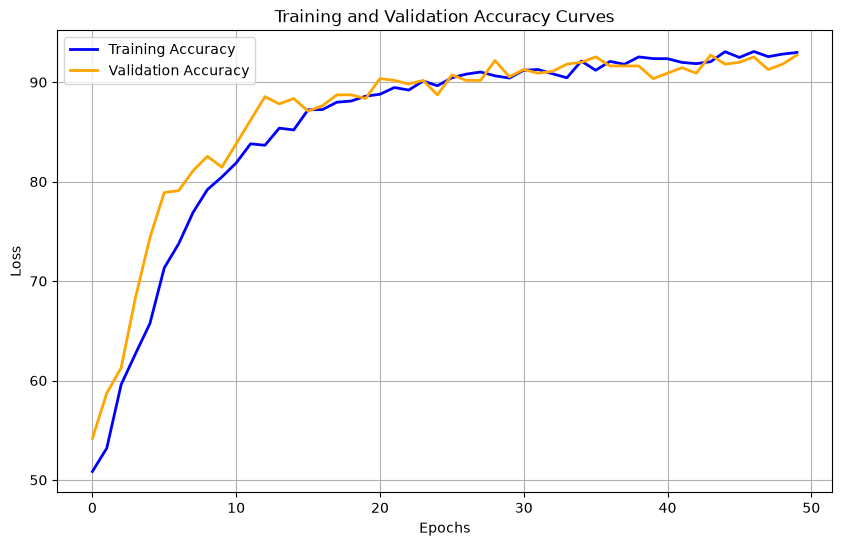

In [ ]:
# previous run -> before reverting the accidental pull

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(acc, label='Training Accuracy', color='blue', linewidth=2)
plt.plot(acc_val, label='Validation Accuracy', color='orange', linewidth=2)
plt.title('Training and Validation Accuracy Curves')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

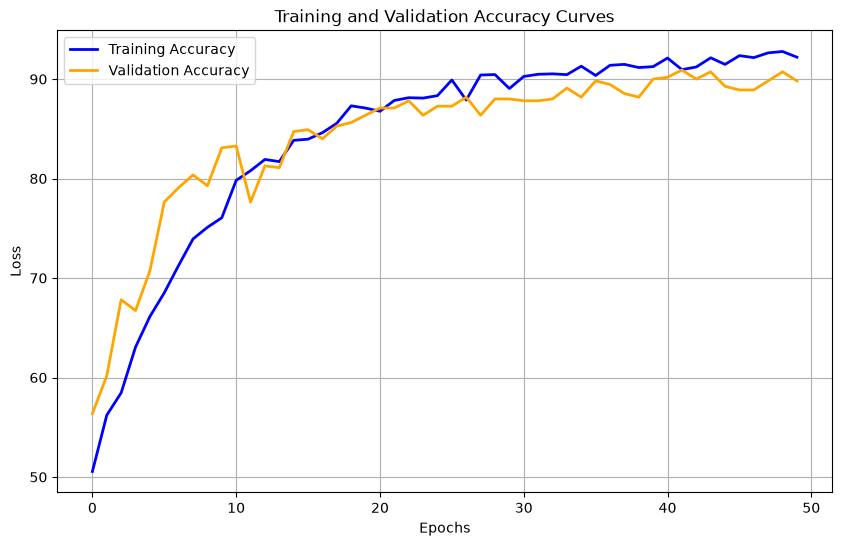

In [98]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(acc, label='Training Accuracy', color='blue', linewidth=2)
plt.plot(acc_val, label='Validation Accuracy', color='orange', linewidth=2)
plt.title('Training and Validation Accuracy Curves')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()